# Start here: AI data centers and their host towns

**ECO 3630 · Baruch College**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/your-github-username/eco3630-ai-datacenters/blob/main/notebooks/00_start_here.ipynb)

This notebook shows every result in a few seconds, then lets you re-run the analysis yourself.

* **Google Colab:** click the badge above, then **Runtime → Run all**. The first cell downloads the project (about 30 seconds).
* **VS Code:** open the project folder, open this notebook, pick your Python as the kernel, then **Run All**.

Nothing to change and no API keys to add: every data source is already saved in `data/`.

| Part | What it does | Time |
|---|---|---|
| 1 | Setup and a check that everything is installed | ~30 s |
| 2 | The saved results: tables and charts | instant |
| 3 | Re-run the regressions yourself | ~3 min |
| 4 | (Optional) Rebuild every table from the raw government files | ~5 min |

## 1. Setup

In [1]:
# Setup: the same cell works in VS Code / Jupyter and in Google Colab.
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/your-github-username/eco3630-ai-datacenters.git"

if "google.colab" in sys.modules:                      # Colab: get the repo first
    target = Path("/content/eco3630-ai-datacenters")
    if not target.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(target)], check=True)
    os.chdir(target)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# find the project folder (the one with src/ in it) and work from there
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))


def run(script, *args):
    """Run scripts/<script> with this notebook's Python and show its output as it goes."""
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}     # Windows-safe printing
    proc = subprocess.Popen([sys.executable, "-u", f"scripts/{script}", *args], env=env,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace")
    for line in proc.stdout:
        print(line, end="")
    if proc.wait():
        raise RuntimeError(f"scripts/{script} stopped with an error (see above)")


print("Working in the project folder:", ROOT.name)

Working in the project folder: eco3630-ai-datacenters


In [2]:
run("check_setup.py")


ECO 3630 AI data center project: setup check

Python
  [OK     ] version 3.13.18 (need 3.10+)
Packages


  [OK     ] pandas 3.1.1
  [OK     ] numpy 2.5.4
  [OK     ] requests 2.34.2


  [OK     ] matplotlib 3.11.2
  [OK     ] statsmodels 0.15.0


  [OK     ] linearmodels 7.1
  [OK     ] dotenv 
  [OK     ] openpyxl 3.1.5
  [OK     ] xlrd 2.0.2


  [OK     ] pdfplumber 0.11.10
  [OK     ] zipcodes 3.0.1
  [OK     ] addfips 0.4.2
  [OK     ] pytest 9.2.0
Folders
  [OK     ] data/raw
  [OK     ] data/processed
  [OK     ] figures
Data files
  [OK     ] data/raw/eia/sales_revenue.xlsx
  [OK     ] data/raw/cfpb
  [OK     ] data/processed/zhvi.csv.gz
  [OK     ] data/processed/elec_utility.csv.gz
  [OK     ] data/processed/delinq.csv
  [OK     ] data/property_tax_controls.csv
  [OK     ] no API keys needed: every source is a saved public file in data/raw/
Site panel
  [OK     ] 80 sites, 21 states, no problems found
  [OK     ] strict AI sample: 17 sites; broad: 37
  [NOTE   ] 5 rows still marked not re-verified (see 'verification')

All checks passed.



## 2. Results

Each row compares the AI host towns with their own matched comparison towns, before and after AI arrived (difference-in-differences).

* **coef:** how much more the hosts changed. In percent, except late mortgages (percentage points).
* **p-value:** the usual regression p-value (standard errors clustered by site).
* **placebo p:** share of fake "host" towns showing an effect at least this big. It needs no standard-error formula, so trust it more with this few sites.
* **coef without top site:** the estimate after dropping the single most influential site.

In [3]:
import pandas as pd
from IPython.display import Image, display

res = pd.read_csv("data/processed/results_did.csv")
table = res[["outcome", "spec", "coef", "se", "pvalue", "perm_p", "n_hosts",
             "most_influential_site", "coef_without_it"]].rename(columns={
    "pvalue": "p-value", "perm_p": "placebo p", "n_hosts": "hosts",
    "most_influential_site": "top site", "coef_without_it": "coef without top site"})
table = table.round(3)
table.astype(object).where(table.notna(), "")   # blanks instead of NaN

,outcome,spec,coef,se,p-value,placebo p,hosts,top site,coef without top site
0,Home values (%),main,0.287,0.958,0.764,0.82,15,58436,-0.419
1,Home values (%),"+ county unemployment, income",0.444,0.717,0.536,,15,,
2,"Home values (%), broad sample",main,1.807,1.115,0.105,0.04,23,35810,1.022
3,"Home values (%), broad sample","+ county unemployment, income",2.619,1.355,0.053,,23,,
4,Rents (%),main,6.398,5.37,0.234,0.0,12,79601,1.024
5,Rents (%),"+ county unemployment, income",3.283,3.354,0.328,,10,,
6,Residential electricity price (%),main,2.94,2.408,0.222,0.283,10,16572_AZ,1.329
7,Mortgages 90+ days late (pct. points),main,0.002,0.046,0.96,0.983,7,39045,-0.039
8,Mortgages 90+ days late (pct. points),"+ county unemployment, income",0.032,0.044,0.472,,7,,
9,Estimated property tax bill (%),main,2.201,4.221,0.602,0.577,9,38109,-1.839


**Rising costs → late mortgages?** Across every CFPB county in the project's states: does faster cost growth go with more mortgages 90+ days late a year later?

In [4]:
med = pd.read_csv("data/processed/results_mediation.csv")
med[["spec", "coef", "se", "pvalue", "n_counties", "months"]].round(4)

,spec,coef,se,pvalue,n_counties,months
0,per 1 SD faster cost index (home values + elec...,-0.0116,0.0126,0.3596,222,2021-01 to 2025-12
1,"per 1 SD faster home value growth only, 12 mon...",-0.0204,0.0081,0.0124,244,2018-01 to 2025-12
2,"per 1 SD faster electricity price growth only,...",0.0041,0.0077,0.5916,222,2021-01 to 2025-12


### Event studies

The gap between hosts and comparison towns in each period around AI's arrival (the dashed line). Before the line, the gap should stay near zero: that is the check that the comparison towns are fair. A jump after the line would be an AI effect.

Home values


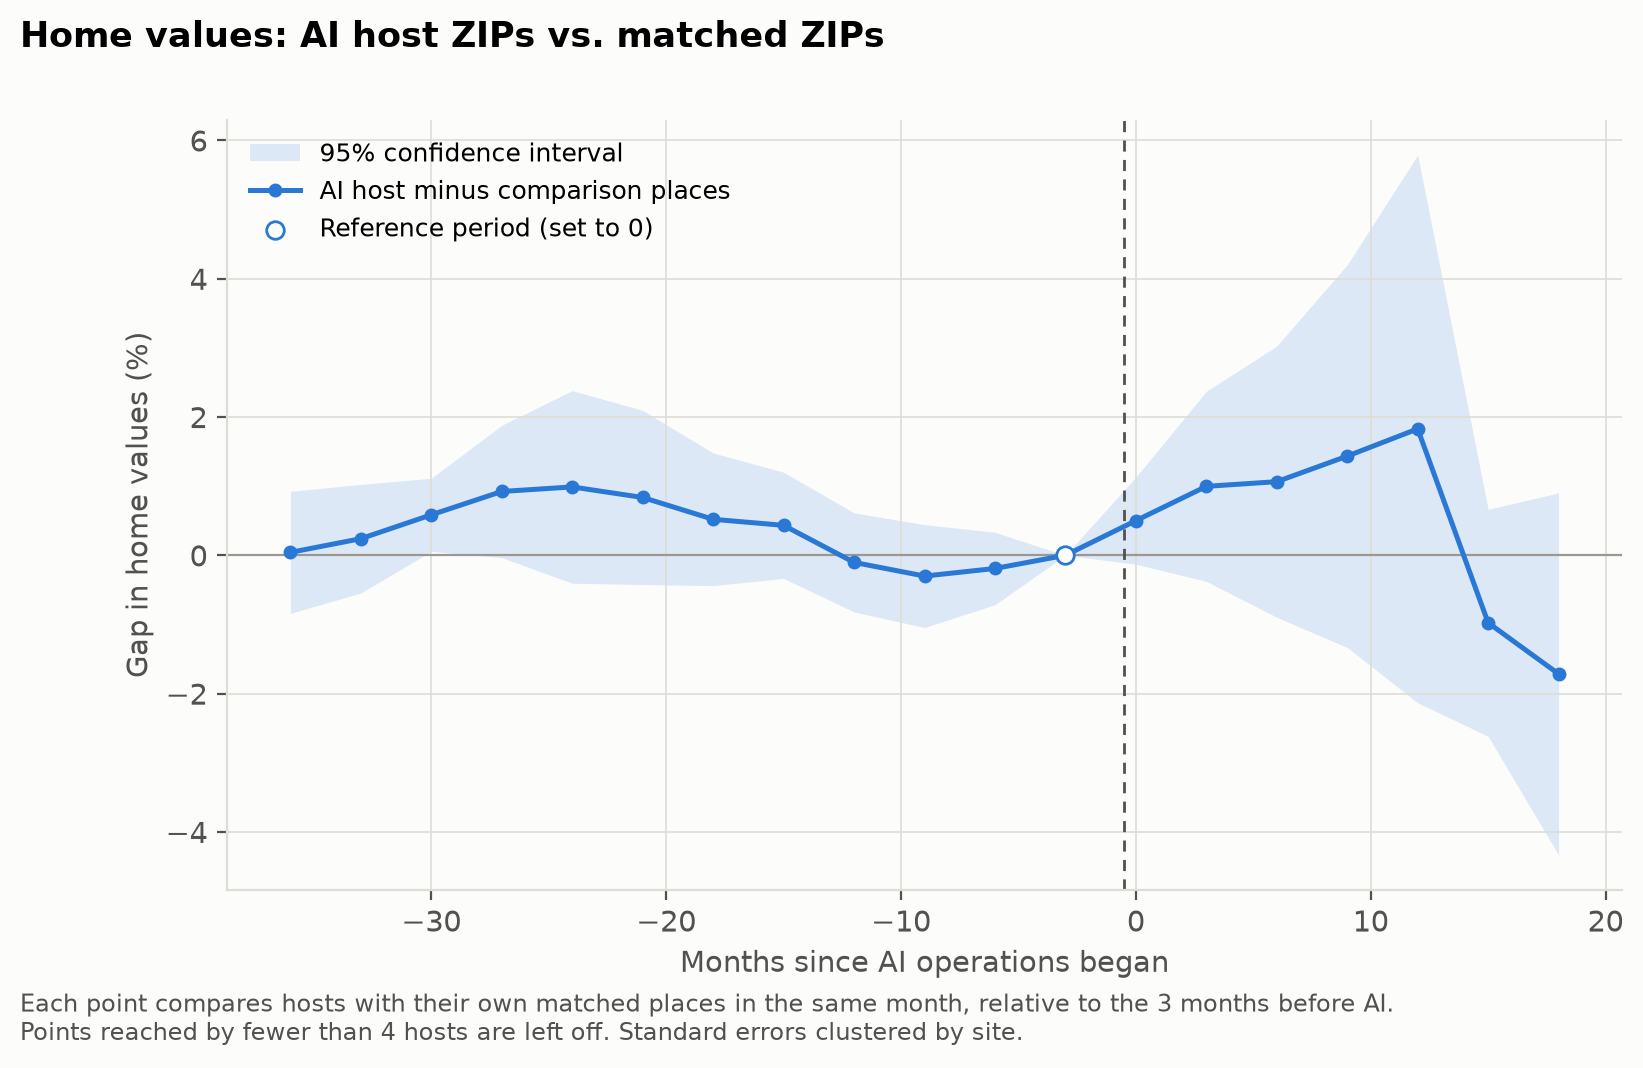

Rents


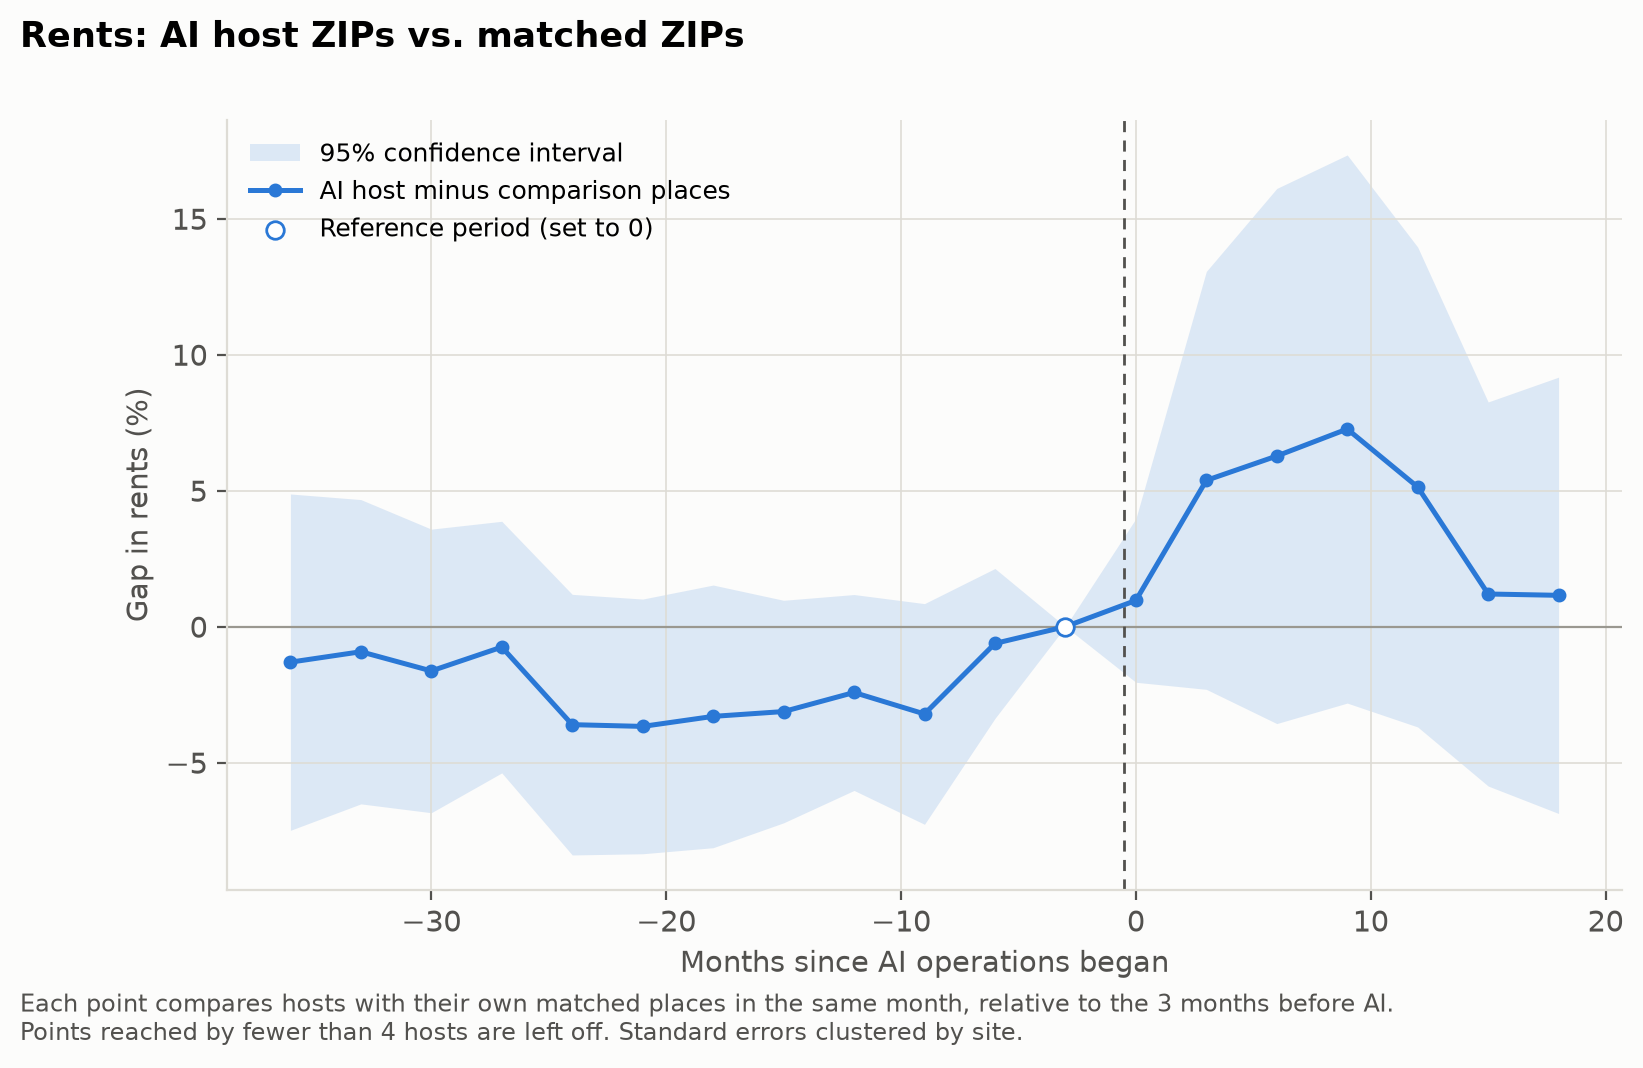

Electricity price (timed at AI start)


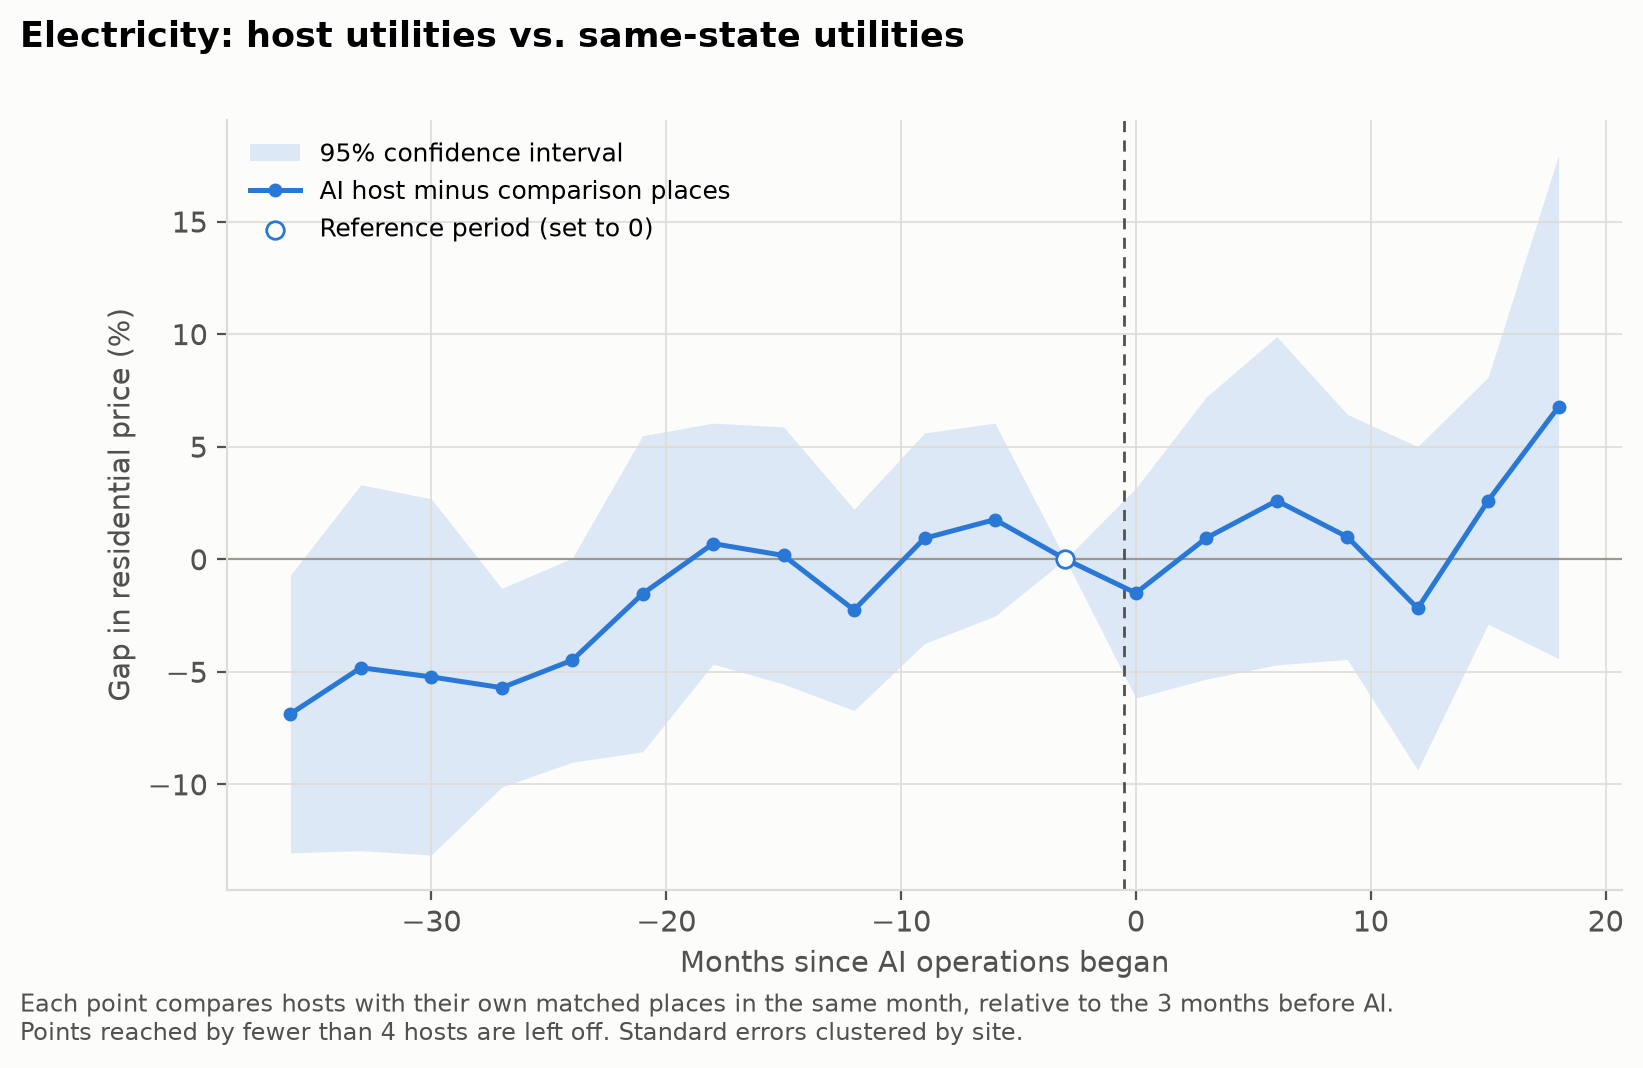

Electricity price (timed at announcement)


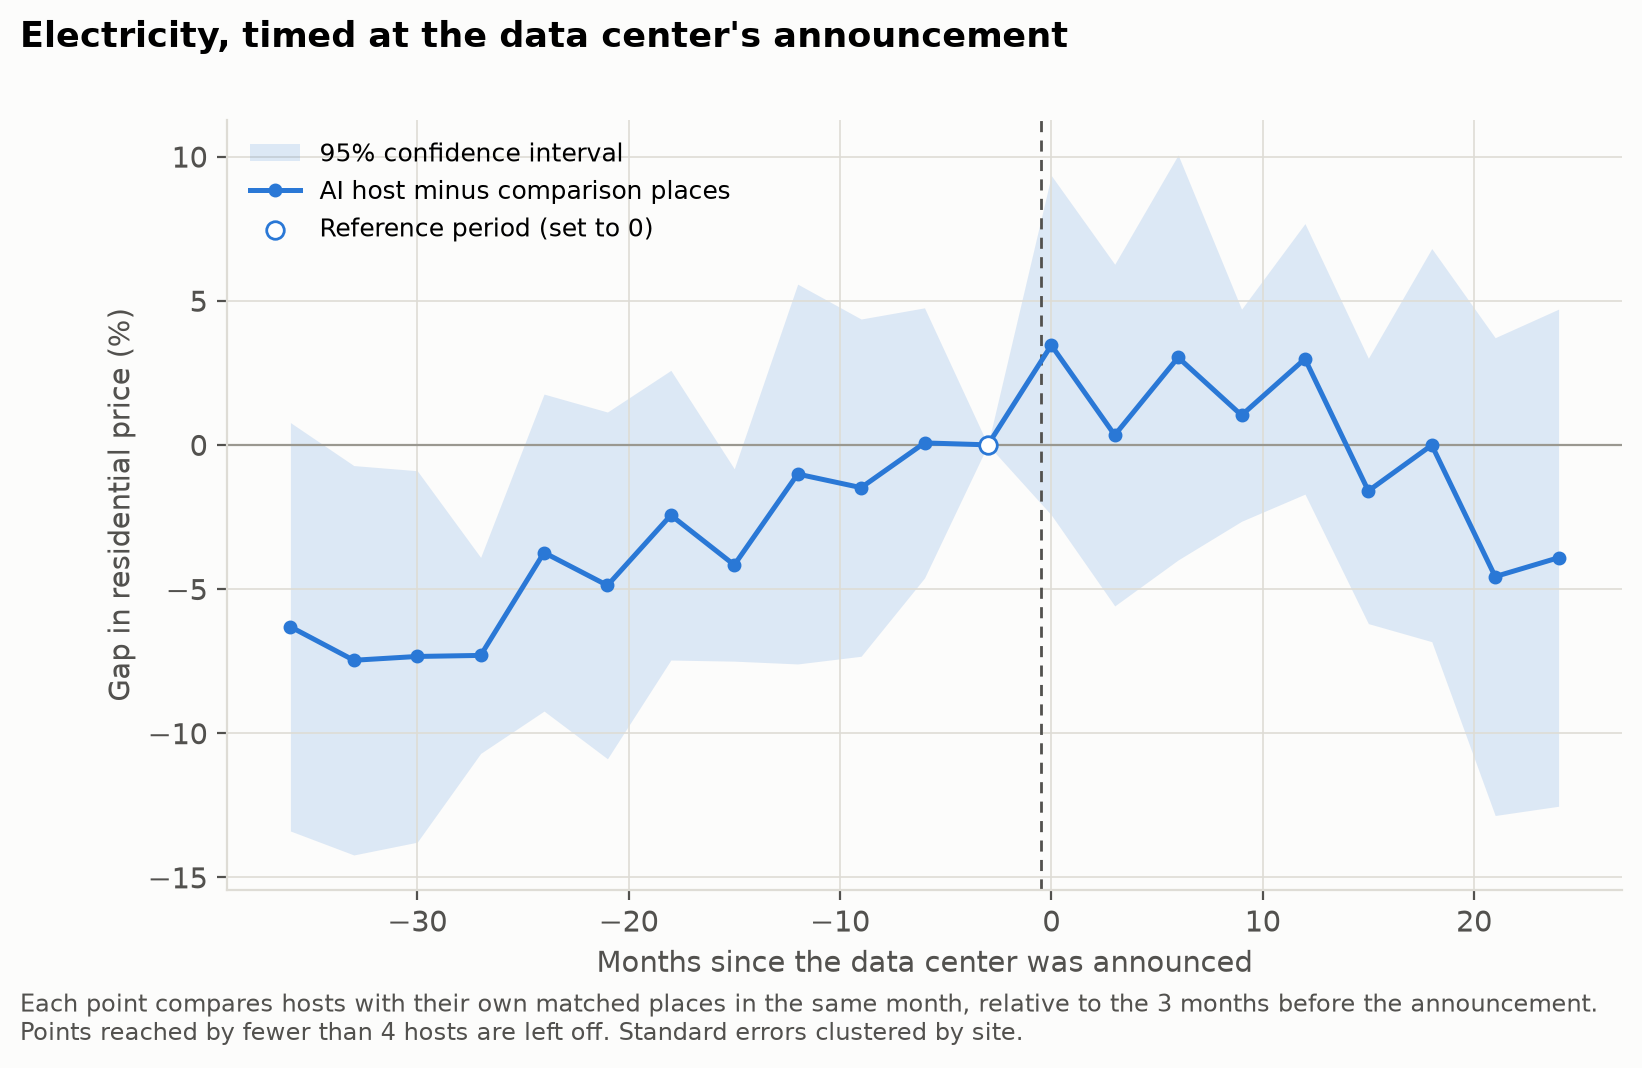

Estimated property tax bill


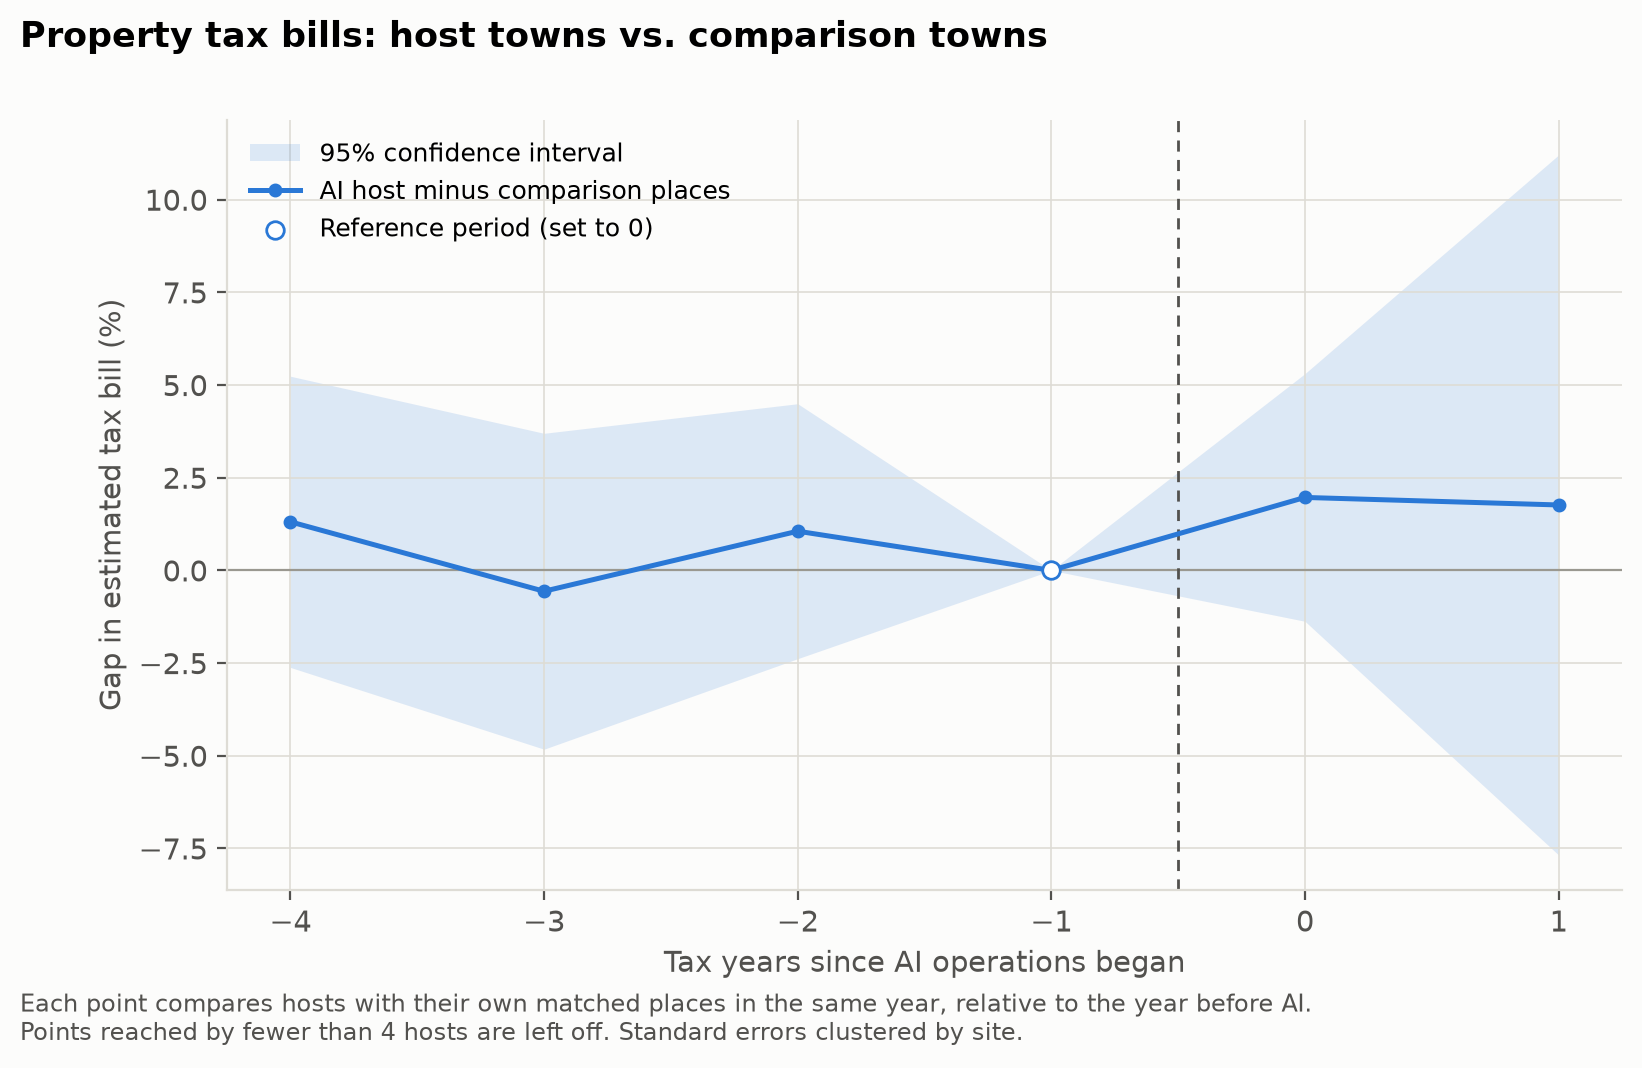

Mortgages 90+ days late


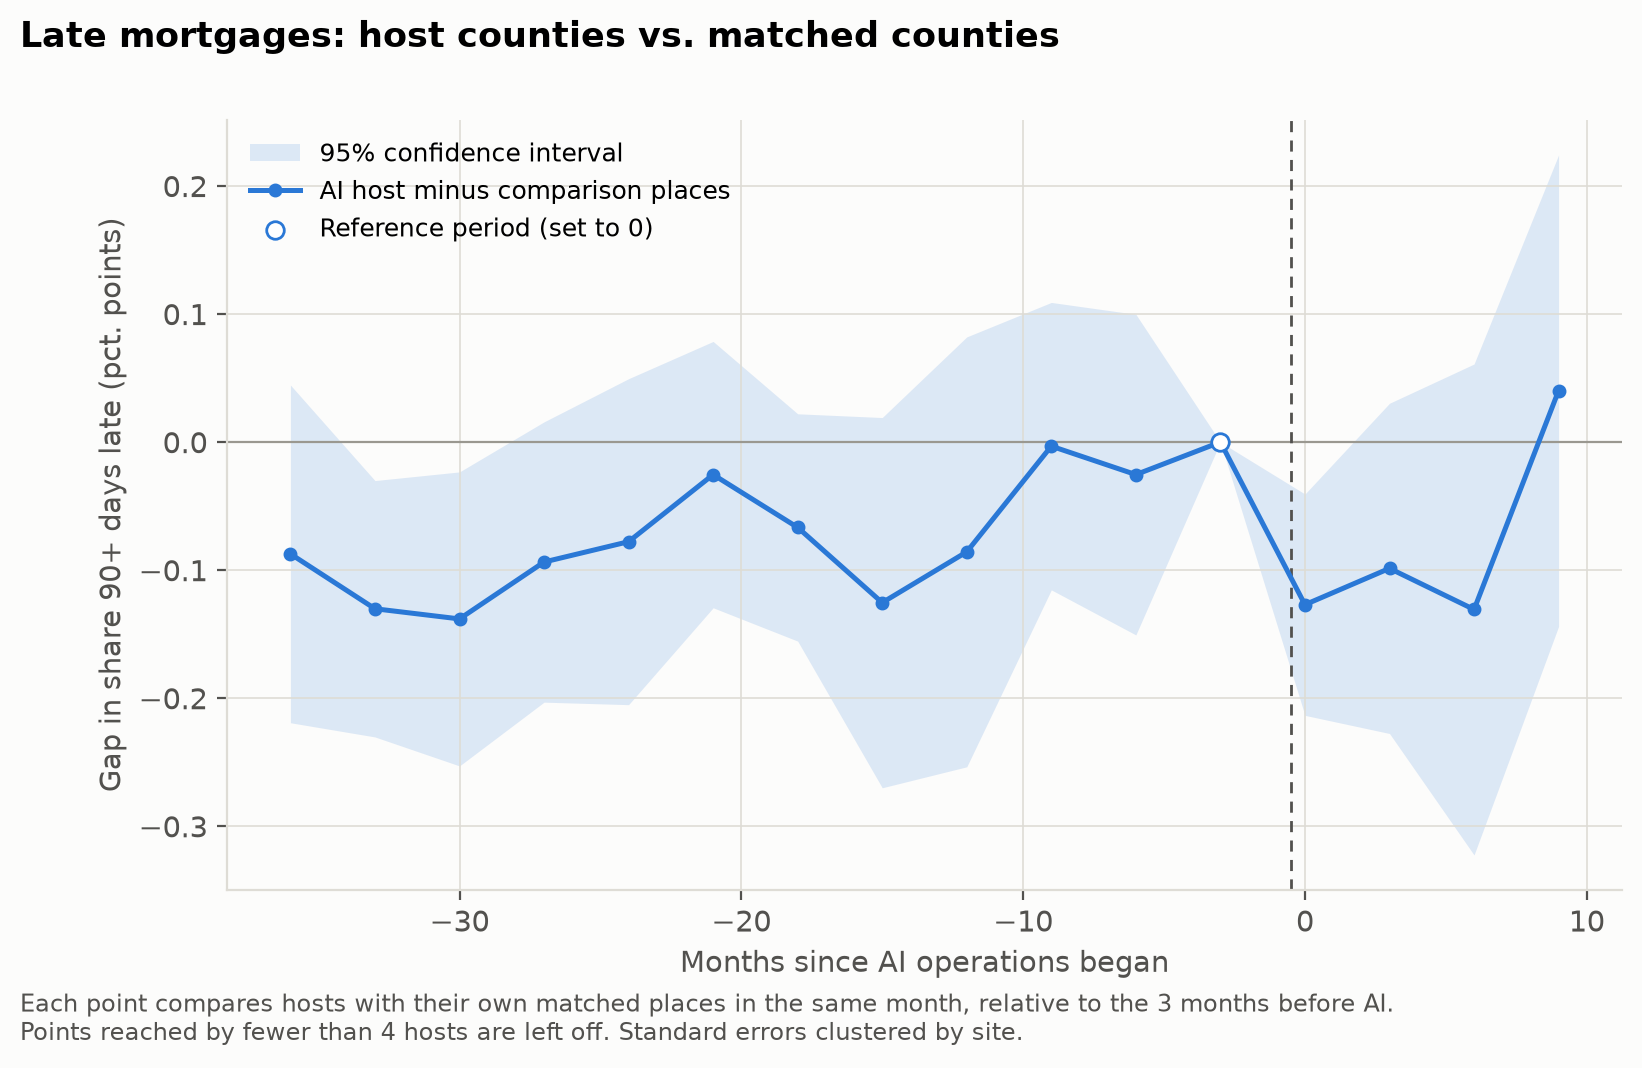

In [5]:
charts = {
    "Home values": "es_zhvi_strict.png",
    "Rents": "es_zori_strict.png",
    "Electricity price (timed at AI start)": "es_elec_strict.png",
    "Electricity price (timed at announcement)": "es_elec_announce.png",
    "Estimated property tax bill": "es_tax_strict.png",
    "Mortgages 90+ days late": "es_delinq_strict.png",
}
for title, f in charts.items():
    print(title)
    display(Image(filename=f"figures/{f}", width=760))

## 3. Re-run the regressions

Rebuilds every number and chart above from the processed data (`data/processed/`). Takes about 3 minutes because of the 300 placebo draws (add `"--quick"` after the script name for a 1-minute version with 50 draws). Then re-run Part 2 to see the fresh output.

In [6]:
run("audit_data.py")
run("run_regressions.py")        # or run("run_regressions.py", "--quick")

             table            variable       rows   places      first       last not_finite out_of_range        min          max host_places_covered host_series_with_gaps
              zhvi                zhvi  1598209.0  12040.0 2015-01-01 2026-09-01        0.0          0.0   13636.31  4977578.862               15/15                   0.0
              zori                zori   469420.0   8340.0 2015-01-01 2026-09-01        0.0        193.0    515.637     103750.0               12/15                   1.0
        elec_state  elec_customers_res    10200.0     51.0 2010-01-01 2026-08-01        0.0          0.0   226548.0   15000882.0                                          
        elec_state      elec_price_com    10200.0     51.0 2010-01-01 2026-08-01        0.0          0.0       5.52       48.048                                          
        elec_state      elec_price_ind    10200.0     51.0 2010-01-01 2026-08-01        0.0          0.0      2.018       43.366                 

zhvi_strict    beta=+0.287 (se 0.958, p=0.764) hosts=15 obs=8,393 | placebo p=0.820 on 15 groups (beta there +0.287) | drop 58436 -> -0.419


zhvi_broad     beta=+1.807 (se 1.115, p=0.105) hosts=23 obs=13,893 | placebo p=0.040 on 23 groups (beta there +1.807) | drop 35810 -> +1.022


zori_strict    beta=+6.398 (se 5.370, p=0.234) hosts=12 obs=2,091 | placebo p=0.000 on 7 groups (beta there +6.157) | drop 79601 -> +1.024


elec_strict    beta=+2.940 (se 2.408, p=0.222) hosts=10 obs=4,487 | placebo p=0.283 on 9 groups (beta there +2.913) | drop 16572_AZ -> +1.329


delinq_strict  beta=+0.002 (se 0.046, p=0.960) hosts=7 obs=1,352 | placebo p=0.983 on 7 groups (beta there +0.002) | drop 39045 -> -0.039


tax_strict     beta=+2.201 (se 4.221, p=0.602) hosts=9 obs=614 | placebo p=0.577 on 9 groups (beta there +2.201) | drop 38109 -> -1.839


elec + trends  beta=-3.370 (se 2.396); at announcement beta=+4.705 (se 1.755, placebo p=0.097, leave-one-out +3.60 to +5.68, drop 16572_AZ -> +3.60)



Costs -> late mortgages (12-month lag):
                                                                     spec    coef     se  pvalue  n_obs  n_counties
per 1 SD faster cost index (home values + electricity), 12 months earlier -0.0116 0.0126  0.3596  13320         222
                per 1 SD faster home value growth only, 12 months earlier -0.0204 0.0081  0.0124  23424         244
         per 1 SD faster electricity price growth only, 12 months earlier  0.0041 0.0077  0.5916  13320         222



Saved: data/processed/results_did.csv, results_mediation.csv, results_event_*.csv; figures/es_*.png


## 4. (Optional) Rebuild everything from the raw files

Turns the saved government downloads in `data/raw/` (Zillow, EIA, CFPB, Census, BLS, FRED, state tax files) back into every processed table, then re-runs the results. The output should match what is already saved. Each step is also its own script; see the pipeline table in `README.md`.

In [7]:
# uncomment to run (about 5-6 minutes)
# run("run_all.py", "--full")